# VQE/VQD eigensolver inside an EPR workflow: single transmon, compared with a Keysight ADS EM simulation

**Pipeline**

1. Keysight ADS (classical EM) gives the *linear* circuit: $C_\Sigma$ (or the linear eigenfrequency $\omega_q$) and the junction inductance $L_J$.
2. EPR quantisation turns these into a nonlinear Hamiltonian (zero-point flux $\varphi_{\rm zpf}$ from the participation $p$).
3. The Hamiltonian is truncated, mapped to qubits, and diagonalised with **VQE** ($E_0$) and **VQD** ($E_1,E_2$).
4. Transition frequencies and anharmonicity are compared with exact diagonalisation, Koch et al., EPR perturbation theory and the ADS linear result.

All energies are in **GHz** (i.e. $h=1$).

| Section | Content |
|---|---|
| 0 | Setup and constants |
| 1 | Transmon Hamiltonian, charge basis |
| 2 | Classical reference and basis convergence |
| 3 | Analytical approximations (Koch, EPR perturbative) |
| 4 | EPR Fock-basis Hamiltonian |
| 5 | Qubit encoding |
| 6 | Ansatz and resources |
| 7 | VQE and VQD |
| 8 | Benchmark: 3 parameter points, 2 depths, 5 starts |
| 9 | Shot noise and depolarising noise |
| 10 | Keysight ADS import and comparison |
| 11 | Summary |

## 0. Setup and constants

Physical constants are needed only to convert ADS quantities ($C$ in fF, $L_J$ in nH) to $E_C$ and $E_J$:

$$E_C=\frac{e^2}{2C_\Sigma},\qquad E_J=\frac{\varphi_0^2}{L_J},\qquad \varphi_0=\frac{\hbar}{2e}=\frac{\Phi_0}{2\pi}.$$

In [1]:
import numpy as np, scipy.linalg as sla, matplotlib.pyplot as plt, pandas as pd, os, time
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector

rng = np.random.default_rng(1234)
h = 6.62607015e-34; e = 1.602176634e-19
phi0 = h/(2*e)/(2*np.pi)                 # reduced flux quantum (Wb)

EC = 0.25                                # GHz (project plan)
RATIOS = [20, 40, 60]                    # EJ/EC
FAST = False                             # True = fewer starts/iterations for a quick test
N_STARTS = 2 if FAST else 5
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})

## 1. Transmon Hamiltonian in the charge basis

$$\hat H = 4E_C(\hat n-n_g)^2 - E_J\cos\hat\varphi .$$

In the charge basis $|n\rangle$, $\hat n$ is diagonal and $\cos\hat\varphi=\tfrac12\sum_n(|n\rangle\langle n+1|+{\rm h.c.})$. We keep $d$ charge states $n=-d/2,\dots,d/2-1$, so $d=2^{n_q}$ maps exactly onto $n_q$ qubits. The matrix is real symmetric.

Transition frequencies and signed anharmonicity:
$$f_{01}=E_1-E_0,\quad f_{12}=E_2-E_1,\quad \alpha=f_{12}-f_{01}.$$

In [2]:
def charge_H(EC, EJ, ng=0.0, dim=16):
    n = np.arange(dim) - dim//2
    off = -0.5*EJ*np.ones(dim-1)
    return np.diag(4*EC*(n-ng)**2) + np.diag(off, 1) + np.diag(off, -1)

def transitions(E):
    f01, f12 = E[1]-E[0], E[2]-E[1]
    return f01, f12, f12-f01

def exact_levels(H, k=3):
    return np.linalg.eigvalsh(H)[:k]

## 2. Classical reference and basis convergence

Basis truncation is one of the three error sources. We increase $d$ until the transition frequencies change by less than 1 MHz (project target). The largest basis is the converged reference.

In [3]:
dims = [4, 8, 16, 32, 64, 128]
rows = []
for r in RATIOS:
    EJ = r*EC
    ref = transitions(exact_levels(charge_H(EC, EJ, dim=dims[-1])))
    for d in dims[:-1]:
        t = transitions(exact_levels(charge_H(EC, EJ, dim=d)))
        rows.append(dict(EJ_EC=r, d=d, f01=t[0], f12=t[1], alpha=t[2],
                         df01_MHz=1e3*(t[0]-ref[0]), df12_MHz=1e3*(t[1]-ref[1])))
conv = pd.DataFrame(rows); print(conv.round(4).to_string(index=False))
REF = {r: transitions(exact_levels(charge_H(EC, r*EC, dim=128))) for r in RATIOS}

 EJ_EC  d    f01    f12   alpha  df01_MHz  df12_MHz
    20  4 3.4575 3.1170 -0.3406  568.8434  592.1042
    20  8 2.8922 2.5362 -0.3560    3.4713   11.3136
    20 16 2.8887 2.5249 -0.3638    0.0000    0.0000
    20 32 2.8887 2.5249 -0.3638    0.0000   -0.0000
    20 64 2.8887 2.5249 -0.3638    0.0000   -0.0000
    40  4 5.9739 6.2580  0.2840 1768.3544 2346.6190
    40  8 4.2509 4.0551 -0.1958   45.3360  143.8086
    40 16 4.2056 3.9113 -0.2942    0.0000    0.0000
    40 32 4.2056 3.9113 -0.2942   -0.0000    0.0000
    40 64 4.2056 3.9113 -0.2942   -0.0000    0.0000
    60  4 8.4644 9.3348  0.8704 3250.1998 4403.5795
    60  8 5.3624 5.3561 -0.0063  148.2683  424.8892
    60 16 5.2142 4.9312 -0.2829    0.0002    0.0023
    60 32 5.2142 4.9312 -0.2829    0.0000    0.0000
    60 64 5.2142 4.9312 -0.2829    0.0000    0.0000


**Choice of encoding.** From the table, $d=16$ (4 qubits) should already be below 1 MHz for all three ratios; `D_ENC` is set below accordingly. Check this before trusting it.

In [4]:
D_ENC, NQ = 16, 4
ok = conv[(conv.d == D_ENC)][["EJ_EC","df01_MHz","df12_MHz"]]
print(ok.round(5).to_string(index=False))
print("All below 1 MHz:", bool((ok[["df01_MHz","df12_MHz"]].abs() < 1).all().all()))

 EJ_EC  df01_MHz  df12_MHz
    20   0.00000   0.00000
    40   0.00000   0.00005
    60   0.00023   0.00227
All below 1 MHz: True


## 3. Analytical approximations

**Koch et al. (2007)**, valid for $E_J/E_C\gg1$:
$$E_m\simeq -E_J+\sqrt{8E_JE_C}\,(m+\tfrac12)-\frac{E_C}{12}(6m^2+6m+3),$$
so $f_{01}\simeq\sqrt{8E_JE_C}-E_C$ and $\alpha\simeq-E_C$.

**EPR perturbation theory** (Minev et al., Eqs. 8–9, single mode, $p_q=1$): the linear frequency is $\omega_q=\sqrt{8E_JE_C}$ and
$$\alpha_{\rm EPR}=\tfrac12\chi_{qq}=\frac{p_q^2(\hbar\omega_q)^2}{8E_J},\qquad f_{01}=\omega_q-\Delta_q,\ \ \Delta_q=\alpha_{\rm EPR}.$$
EPR defines $H\supset-\tfrac{\alpha}{2}a^{\dagger2}a^2$, so $\alpha_{\rm EPR}>0$ corresponds to **signed** anharmonicity $f_{12}-f_{01}=-\alpha_{\rm EPR}$.

In [5]:
def koch(EC, EJ):
    Em = lambda m: -EJ + np.sqrt(8*EJ*EC)*(m+.5) - EC/12*(6*m*m+6*m+3)
    return transitions([Em(0), Em(1), Em(2)])

def epr_pert(f_lin, EJ, p=1.0):
    a = p**2*f_lin**2/(8*EJ)          # alpha_EPR (positive)
    f01 = f_lin - a
    return f01, f01 - a, -a            # f01, f12, signed alpha

for r in RATIOS:
    EJ = r*EC; fl = np.sqrt(8*EJ*EC)
    print(f"EJ/EC={r}: exact {np.round(REF[r],4)} | Koch {np.round(koch(EC,EJ),4)} | EPR-pert {np.round(epr_pert(fl,EJ),4)}")

EJ/EC=20: exact [ 2.8887  2.5249 -0.3638] | Koch [ 2.9123  2.6623 -0.25  ] | EPR-pert [ 2.9123  2.6623 -0.25  ]
EJ/EC=40: exact [ 4.2056  3.9113 -0.2942] | Koch [ 4.2221  3.9721 -0.25  ] | EPR-pert [ 4.2221  3.9721 -0.25  ]
EJ/EC=60: exact [ 5.2142  4.9312 -0.2829] | Koch [ 5.2272  4.9772 -0.25  ] | EPR-pert [ 5.2272  4.9772 -0.25  ]


## 4. EPR Hamiltonian in the Fock basis

EPR gives the linear mode frequency $\omega_q$ and the junction participation $p_q$ from one eigenmode simulation. The zero-point flux across the junction is (Eq. 7 / A.54)
$$\varphi_{\rm zpf}^2=p_q\frac{\hbar\omega_q}{2E_J},\qquad \hat\varphi=\varphi_{\rm zpf}(\hat a+\hat a^\dagger).$$
The full Hamiltonian (Eqs. 2–3) is
$$\hat H=\hbar\omega_q\hat a^\dagger\hat a-E_J\Big[\cos\hat\varphi+\tfrac12\hat\varphi^2\Big].$$
The $\tfrac12\hat\varphi^2$ term removes the harmonic part already counted in $\hbar\omega_q\hat a^\dagger\hat a$, leaving only the nonlinearity.

For $p_q=1$, $\hbar\omega_q=\sqrt{8E_JE_C}$ this is the same operator as the charge-basis transmon, so it is an independent cross-check of the encoding.

**Numerical care:** $\cos\hat\varphi$ must be computed as a matrix function in a *large* Fock space, then truncated to $d$ levels. Truncating the Taylor series first gives wrong levels.

**Two effects visible in the table below** (both physical, not bugs):
- *Residual offset vs the charge basis.* The Fock model uses the non-compact flux variable (as in EPR), so it has no charge dispersion; the charge-basis reference at $n_g=0$ does. The offset is largest for $f_{12}$ at $E_J/E_C=20$ (tens of MHz) and falls rapidly with $E_J/E_C$. It does not shrink with $d$.
- *Cutoff must not be too large.* The non-compact cosine potential has identical wells at $\varphi=2\pi k$. A very large $d$ (here $\gtrsim28$ at $E_J/E_C=20$) admits spurious states in neighbouring wells (the multiple-minima/phase-slip caveat in the EPR supplement). Keep $d$ just large enough to converge the lowest three levels.

In [6]:
def fock_H(f_lin, EJ, p=1.0, d=16, Nbig=150):
    zpf = np.sqrt(p*f_lin/(2*EJ))
    a = np.diag(np.sqrt(np.arange(1, Nbig)), 1)
    phi = zpf*(a + a.T)
    cosphi = sla.cosm(phi) if hasattr(sla, "cosm") else sla.expm(1j*phi).real
    Hbig = np.diag(f_lin*np.arange(Nbig)) - EJ*(cosphi + 0.5*phi@phi)
    return Hbig[:d, :d]

print("Fock-basis EPR vs charge-basis reference (MHz difference in f01, f12):")
for r in RATIOS:
    EJ = r*EC; fl = np.sqrt(8*EJ*EC)
    for d in (8, 12, 16, 20, 24):
        t = transitions(exact_levels(fock_H(fl, EJ, 1.0, d)))
        print(f"EJ/EC={r:>2} d={d:>2}: {1e3*(t[0]-REF[r][0]):8.3f} {1e3*(t[1]-REF[r][1]):8.3f}")

Fock-basis EPR vs charge-basis reference (MHz difference in f01, f12):
EJ/EC=20 d= 8:   -1.902   50.147
EJ/EC=20 d=12:   -2.156   37.042
EJ/EC=20 d=16:   -2.176   35.182
EJ/EC=20 d=20:   -2.180   34.445
EJ/EC=20 d=24:   -2.182   32.988
EJ/EC=40 d= 8:    0.014    4.019
EJ/EC=40 d=12:   -0.029    0.951
EJ/EC=40 d=16:   -0.030    0.841
EJ/EC=40 d=20:   -0.030    0.834
EJ/EC=40 d=24:   -0.030    0.833
EJ/EC=60 d= 8:    0.016    1.458
EJ/EC=60 d=12:   -0.001    0.060
EJ/EC=60 d=16:   -0.001    0.034
EJ/EC=60 d=20:   -0.001    0.034
EJ/EC=60 d=24:   -0.001    0.034


## 5. Qubit encoding

A $d=2^{n_q}$-dimensional real symmetric matrix is expanded in Pauli strings,
$$\hat H=\sum_k c_k P_k,\qquad P_k\in\{I,X,Y,Z\}^{\otimes n_q},$$
which is the form measured on hardware (each $P_k$, or each commuting group, is one measurement setting). Binary (compact) encoding uses $n_q=\log_2 d$ qubits.

In [7]:
def pauli_decompose(H):
    op = SparsePauliOp.from_operator(H).simplify(atol=1e-12)
    coeffs = op.coeffs.real
    mats = np.array([p.to_matrix() for p in op.paulis]).real if all(
        set(str(p)) <= set("IXZ") or str(p).count("Y") % 2 == 0 for p in op.paulis) else \
        np.array([p.to_matrix() for p in op.paulis])
    return op, coeffs, mats

H_demo = charge_H(EC, 40*EC, dim=D_ENC)
op_demo, c_demo, P_demo = pauli_decompose(H_demo)
print("n_qubits =", NQ, "| Pauli terms =", len(op_demo))
print("reconstruction error:", np.abs(op_demo.to_matrix() - H_demo).max())

n_qubits = 4 | Pauli terms = 26
reconstruction error: 0.0


## 6. Variational ansatz and resource counting

Because $\hat H$ is real, a real-amplitude hardware-efficient ansatz is enough: $R_Y$ layers separated by a linear CX chain,
$$|\psi(\boldsymbol\theta)\rangle=\prod_{r}\Big[\textstyle\prod_q R_Y(\theta_{r,q})\Big]\,[\text{CX chain}]\cdots|0\rangle,$$
with `reps` entangling blocks and $n_q(\text{reps}+1)$ parameters. Two depths are compared (`reps` = 2 and 3).

The optimiser uses a fast NumPy statevector. The identical circuit is also built in Qiskit for gate counts, depth, and a cross-check.

In [8]:
def ansatz_circuit(n, reps):
    th = ParameterVector("t", n*(reps+1)); qc = QuantumCircuit(n); k = 0
    for r in range(reps+1):
        for q in range(n): qc.ry(th[k], q); k += 1
        if r < reps:
            for q in range(n-1): qc.cx(q, q+1)
    return qc, th

def ansatz_state(params, n, reps):
    psi = np.zeros((2,)*n); psi[(0,)*n] = 1.0; k = 0
    for r in range(reps+1):
        for q in range(n):
            ax = n-1-q; t = params[k]; k += 1
            c, s = np.cos(t/2), np.sin(t/2)
            psi = np.moveaxis(np.tensordot(np.array([[c, -s], [s, c]]), psi, axes=([1], [ax])), 0, ax)
        if r < reps:
            for q in range(n-1):
                axc, axt = n-1-q, n-2-q
                idx = [slice(None)]*n; idx[axc] = 1
                sub = psi[tuple(idx)]
                psi[tuple(idx)] = np.flip(sub, axis=axt-1 if axt > axc else axt)
    return psi.reshape(-1)

# cross-check NumPy vs Qiskit and collect resources
RES = {}
for reps in (2, 3):
    qc, th = ansatz_circuit(NQ, reps)
    x = rng.uniform(0, 2*np.pi, len(th))
    psi_q = Statevector(qc.assign_parameters(dict(zip(th, x)))).data
    err = np.abs(psi_q - ansatz_state(x, NQ, reps)).max()
    tq = transpile(qc, basis_gates=["ry", "cx"], optimization_level=0)
    RES[reps] = dict(n_params=len(th), depth=tq.depth(), cx=tq.count_ops().get("cx", 0))
    print(f"reps={reps}: params={len(th)}, depth={RES[reps]['depth']}, CX={RES[reps]['cx']}, NumPy-vs-Qiskit max err={err:.1e}")

reps=2: params=12, depth=8, CX=6, NumPy-vs-Qiskit max err=0.0e+00
reps=3: params=16, depth=11, CX=9, NumPy-vs-Qiskit max err=0.0e+00


## 7. VQE and VQD

**VQE** minimises $E(\boldsymbol\theta)=\langle\psi(\boldsymbol\theta)|\hat H|\psi(\boldsymbol\theta)\rangle\ge E_0$.

**VQD** (Higgott et al.) finds level $j$ by penalising overlap with the already-found states $|\psi_i\rangle$, $i<j$:
$$C_j(\boldsymbol\theta)=\langle\hat H\rangle_{\boldsymbol\theta}+\sum_{i<j}\beta_i\,|\langle\psi_i|\psi(\boldsymbol\theta)\rangle|^2 .$$
$\beta$ must exceed the gap $E_j-E_i$ (here $\beta=3\,\omega_q$). Errors in $|\psi_i\rangle$ propagate to higher levels, so $E_2$ is the least reliable.

Each level is optimised from several random starts; the lowest **cost** is carried forward. The energy function is pluggable (ideal, shot noise, depolarising); overlaps are evaluated exactly here (on hardware they need a swap or compute-uncompute test). Counts of energy and overlap evaluations are recorded.

In [9]:
def run_vqd(H, n, reps, n_levels=3, beta=20.0, starts=5, energy_fn=None,
            method="L-BFGS-B", maxiter=400, seed=0):
    r = np.random.default_rng(seed)
    energy = energy_fn or (lambda psi: psi @ H @ psi)
    prev, out = [], []
    npar = n*(reps+1)
    for j in range(n_levels):
        runs = []
        for s in range(starts):
            x0 = r.uniform(0, 2*np.pi, npar); hist = []; cnt = [0]
            def cost(x):
                psi = ansatz_state(x, n, reps); cnt[0] += 1
                c = energy(psi) + sum(beta*(p @ psi)**2 for p in prev)
                hist.append(c); return c
            if method == "COBYLA":
                res = minimize(cost, x0, method="COBYLA", options=dict(maxiter=maxiter, rhobeg=0.6))
            else:
                res = minimize(cost, x0, method=method, options=dict(maxiter=maxiter))
            psi = ansatz_state(res.x, n, reps)
            runs.append(dict(cost=res.fun, E=energy(psi) if energy_fn is None else psi @ H @ psi,
                             x=res.x, psi=psi, nfev=cnt[0], hist=np.minimum.accumulate(hist),
                             overlap_evals=cnt[0]*len(prev)))
        out.append(runs)
        prev.append(min(runs, key=lambda d: d["cost"])["psi"])
    return out

def summarise(runs_by_level):
    # per-start energies for each level (start s uses its own level-0..j-1 only via best-chain)
    return [np.array([r["E"] for r in lvl]) for lvl in runs_by_level]

# quick demo: EJ/EC = 40, reps = 3
r_ = 40; EJ_ = r_*EC; H_ = charge_H(EC, EJ_, dim=D_ENC); fl_ = np.sqrt(8*EJ_*EC)
t0 = time.time(); demo = run_vqd(H_, NQ, 3, beta=3*fl_, starts=N_STARTS); print(f"{time.time()-t0:.1f}s")
exact = exact_levels(H_)
best = [min(l, key=lambda d: d["cost"]) for l in demo]
Ev = np.array([b["E"] for b in best])
print("exact E:", exact.round(5)); print("VQE/VQD:", Ev.round(5))
print("f01,f12,alpha VQ:", np.round(transitions(Ev), 5)); print("             exact:", np.round(transitions(exact), 5))

10.3s
exact E: [-7.82835 -3.62277  0.28857]
VQE/VQD: [-7.82835 -3.62277  0.28857]
f01,f12,alpha VQ: [ 4.20558  3.91134 -0.29424]
             exact: [ 4.20558  3.91134 -0.29425]


## 8. Benchmark: three parameter points, two depths, five starts

For each $E_J/E_C\in\{20,40,60\}$ and each depth we report the **best-start** result and the **variability across starts** (std of the level-wise energies). Errors are against the converged classical reference. Anharmonicity is a difference of transitions, so its absolute error is reported separately.

In [10]:
BENCH = {}
rows = []
for r in RATIOS:
    EJ = r*EC; fl = np.sqrt(8*EJ*EC); H = charge_H(EC, EJ, dim=D_ENC)
    ref = REF[r]
    for reps in (2, 3):
        runs = run_vqd(H, NQ, reps, beta=3*fl, starts=N_STARTS, seed=r*10+reps)
        BENCH[(r, reps)] = runs
        best = [min(l, key=lambda d: d["cost"]) for l in runs]
        Ev = np.array([b["E"] for b in best]); t = transitions(Ev)
        Estd = [np.std([x["E"] for x in l]) for l in runs]
        nfev = sum(x["nfev"] for l in runs for x in l); nov = sum(x["overlap_evals"] for l in runs for x in l)
        rows.append(dict(EJ_EC=r, reps=reps, f01=t[0], f12=t[1], alpha=t[2],
                         err_f01_pct=100*abs(t[0]-ref[0])/ref[0], err_f12_pct=100*abs(t[1]-ref[1])/ref[1],
                         err_alpha_MHz=1e3*abs(t[2]-ref[2]), spread_E0_MHz=1e3*Estd[0], spread_E1_MHz=1e3*Estd[1], spread_E2_MHz=1e3*Estd[2],
                         depth=RES[reps]["depth"], CX=RES[reps]["cx"], energy_evals=nfev, overlap_evals=nov))
bench = pd.DataFrame(rows); print(bench.round(5).to_string(index=False))
for reps in (2, 3):
    b = bench[bench.reps == reps]
    print(f"reps={reps}: ideal f01,f12 within 1% of classical at all points:",
          bool(((b.err_f01_pct < 1) & (b.err_f12_pct < 1)).all()))

 EJ_EC  reps     f01     f12    alpha  err_f01_pct  err_f12_pct  err_alpha_MHz  spread_E0_MHz  spread_E1_MHz  spread_E2_MHz  depth  CX  energy_evals  overlap_evals
    20     2 3.09468 2.09690 -0.99778      7.13039     16.95060      633.95859        0.17243      402.27567      189.09317      8   6         19318          22347
    20     3 2.88871 2.52488 -0.36382      0.00000      0.00000        0.00008       50.44261        1.51772        0.19060     11   9         39083          38114
    40     2 4.40258 3.78364 -0.61894      4.68419      3.26486      324.69717     1606.56023        0.00274       44.21964      8   6         28028          24323
    40     3 4.20558 3.91134 -0.29425      0.00000      0.00000        0.00005        0.95597        0.00001        6.18207     11   9         28713          27710
    60     2 5.42229 4.93022 -0.49207      3.99154      0.02047      209.13478     1072.25230        0.00217        0.00338      8   6         32617          38298
    60     3 5.2

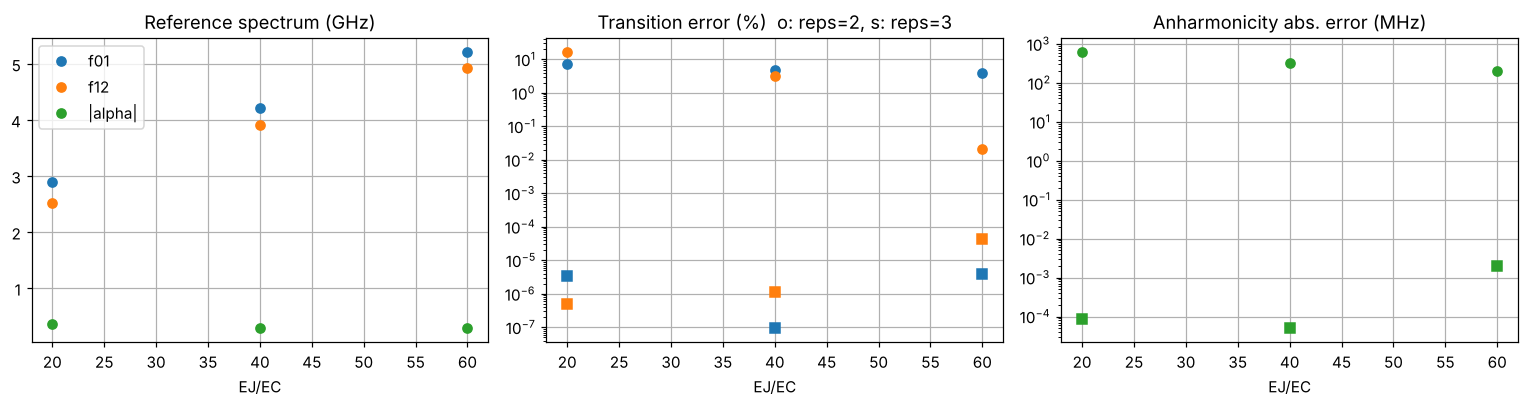

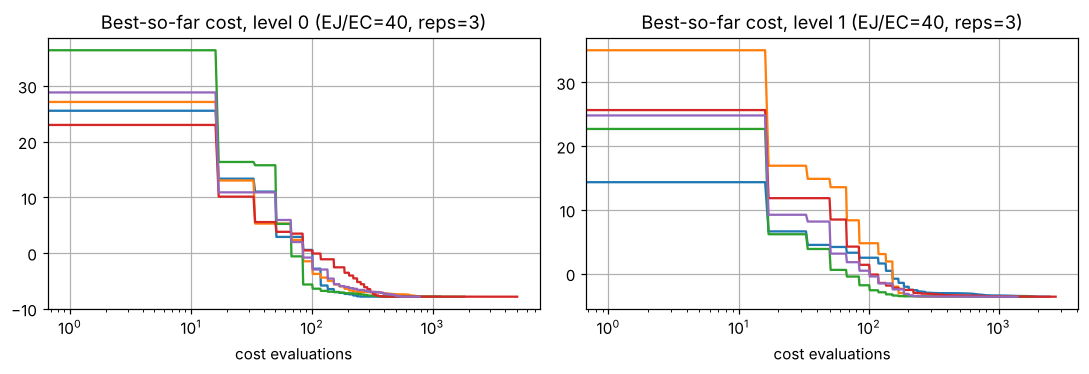

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
# spectrum
for r in RATIOS:
    for reps, mk in ((2, "o"), (3, "s")):
        b = bench[(bench.EJ_EC == r) & (bench.reps == reps)].iloc[0]
        ax[1].plot(r, b.err_f01_pct, mk, c="C0"); ax[1].plot(r, b.err_f12_pct, mk, c="C1")
        ax[2].plot(r, b.err_alpha_MHz, mk, c="C2")
    ax[0].plot([r]*3, REF[r][:2] + (REF[r][2],), "k.")
ax[0].cla(); ax[0].set_title("Reference spectrum (GHz)")
for r in RATIOS:
    ax[0].plot(r, REF[r][0], "o", c="C0"); ax[0].plot(r, REF[r][1], "o", c="C1"); ax[0].plot(r, abs(REF[r][2]), "o", c="C2")
ax[0].legend(["f01", "f12", "|alpha|"]); ax[0].set_xlabel("EJ/EC")
ax[1].set_title("Transition error (%)  o: reps=2, s: reps=3"); ax[1].set_yscale("log"); ax[1].set_xlabel("EJ/EC")
ax[2].set_title("Anharmonicity abs. error (MHz)"); ax[2].set_yscale("log"); ax[2].set_xlabel("EJ/EC")
plt.tight_layout(); plt.show()

# convergence of optimisation (EJ/EC = 40, reps = 3, level 0 and 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for j in (0, 1):
    for x in BENCH[(40, 3)][j]: ax[j].plot(x["hist"])
    ax[j].set_title(f"Best-so-far cost, level {j} (EJ/EC=40, reps=3)"); ax[j].set_xlabel("cost evaluations"); ax[j].set_xscale("log")
plt.tight_layout(); plt.show()

## 9. Measurement noise

**(a) Finite shots, at fixed ideal parameters.** This isolates measurement noise from optimisation error. Each Pauli term is estimated from $N$ projective measurements, $\hat e_k=2\,{\rm Binomial}(N,\tfrac{1+e_k}{2})/N-1$ and $E=\sum_kc_k\hat e_k$, so
$${\rm Var}(E)=\sum_k c_k^2\frac{1-e_k^2}{N}.$$
No qubit grouping is used (worst case). The number of shots per level for a target accuracy $\sigma$ is $N=\sum_kc_k^2(1-e_k^2)/\sigma^2$.

**Important:** the Hamiltonian contains $4E_Cn^2$ up to $n=8$ (tens of GHz), so the Pauli coefficients are large compared with the MHz-scale transitions. Shot noise is therefore large unless the encoding is reduced or terms are grouped. This is a genuine resource finding, not a bug.

**(b) Global depolarising proxy.** A circuit with $N_{\rm CX}$ two-qubit gates of error $p_2$ has fidelity $F=(1-p_2)^{N_{\rm CX}}$. With $\lambda=1-F$, $\langle H\rangle\to(1-\lambda)\langle H\rangle+\lambda\,{\rm Tr}H/d$, which rescales all transition frequencies by $(1-\lambda)$. It is a rough proxy, not a hardware model. For a real device model use `qiskit-aer` with a noise model (optional extension).

In [12]:
r0, reps0 = 40, 3
EJ = r0*EC; fl = np.sqrt(8*EJ*EC); H = charge_H(EC, EJ, dim=D_ENC)
op, cf, Pm = pauli_decompose(H)
psis = [min(l, key=lambda d: d["cost"])["psi"] for l in BENCH[(r0, reps0)]]   # ideal VQE/VQD states

def pauli_exp(psi): return np.einsum("i,kij,j->k", psi, Pm, psi)
var1 = [np.sum(cf**2*(1-pauli_exp(p)**2)) for p in psis]                      # Var(E_j) * N
for j, v in enumerate(var1): print(f"level {j}: shots for 1 MHz std on E{j}: {v/1e-6:.2e}")

rows = []
for N in (10**3, 10**4, 10**5, 10**6):
    r_ = np.random.default_rng(N); reps_ = 100
    est = np.zeros((reps_, 3))
    for i in range(reps_):
        for j, p in enumerate(psis):
            ex = pauli_exp(p); est[i, j] = cf @ (2*r_.binomial(N, np.clip((1+ex)/2, 0, 1))/N - 1)
    t = np.array([transitions(x) for x in est]); ref = transitions(np.array([p@H@p for p in psis]))
    rows.append(dict(shots_per_term=N, std_f01_MHz=1e3*t[:, 0].std(), std_f12_MHz=1e3*t[:, 1].std(),
                     std_alpha_MHz=1e3*t[:, 2].std(), bias_f01_MHz=1e3*(t[:, 0].mean()-ref[0])))
print(pd.DataFrame(rows).round(3).to_string(index=False))

# depolarising proxy
Hbar = np.trace(H)/H.shape[0]; ideal = transitions(exact_levels(H))
print("\nDepolarising proxy (reps=3):")
for p in [0, 1e-3, 5e-3, 1e-2, 2e-2]:
    lam = 1 - (1-p)**RES[3]["cx"]
    t = transitions((1-lam)*exact_levels(H) + lam*Hbar)
    print(f"p2={p:.0e}: lambda={lam:.3f}  f01={t[0]:.4f}  (error {1e3*(t[0]-ideal[0]):.1f} MHz)")

level 0: shots for 1 MHz std on E0: 8.16e+07
level 1: shots for 1 MHz std on E1: 1.42e+08
level 2: shots for 1 MHz std on E2: 1.74e+08
 shots_per_term  std_f01_MHz  std_f12_MHz  std_alpha_MHz  bias_f01_MHz
           1000      484.175      559.143        926.166       -42.779
          10000      142.995      170.488        276.724        -8.916
         100000       47.599       52.288         87.694        -3.366
        1000000       12.551       18.835         28.104         1.158

Depolarising proxy (reps=3):
p2=0e+00: lambda=0.000  f01=4.2056  (error 0.0 MHz)
p2=1e-03: lambda=0.009  f01=4.1679  (error -37.7 MHz)
p2=5e-03: lambda=0.044  f01=4.0201  (error -185.5 MHz)
p2=1e-02: lambda=0.086  f01=3.8419  (error -363.7 MHz)
p2=2e-02: lambda=0.166  f01=3.5064  (error -699.2 MHz)


## 10. Keysight ADS comparison

### What to take from ADS

ADS (Momentum or FEM) solves the **linear** electromagnetic problem. It does not give anharmonicity directly, which is exactly why the EPR step is needed. Extract:

1. **$C_\Sigma$**: simulate the qubit pads (two ports, one on each pad, referenced to ground) and export Y-parameters at low frequency (quasi-static, well below the first resonance). Use `c_from_y` below. Alternatively read $C_\Sigma$ from the ADS capacitance extraction.
2. **$L_J$**: the junction as a lumped inductor, $L_J=\varphi_0^2/E_J$ (from room-temperature resistance via Ambegaokar–Baratoff, as in the EPR paper).
3. **Linear eigenfrequency $f_{\rm lin}$** (optional, preferred if available): terminate the junction port with $L_J$ and find the resonance where ${\rm Im}\,Y=0$ (or the S-parameter peak). It includes distributed effects that the lumped $1/(2\pi\sqrt{LC})$ misses.
4. **Participation $p_J$**: $p=1$ for a lumped, junction-dominated mode. For distributed layouts, $p_J=\tfrac12L_J|I_J|^2/E_{\rm ind}$ (Eq. C.6), or $p=1-E_{\rm mag}/E_{\rm elec}$ for a single junction (Eq. C.2).

### What is compared

| Quantity | Source |
|---|---|
| $f_{\rm lin}$ | ADS only (harmonic, no nonlinearity) |
| $f_{01}$, $f_{12}$, $\alpha$ | EPR Hamiltonian, exact diagonalisation |
| same | EPR Hamiltonian, VQE/VQD |
| same | EPR first-order perturbation theory |

The expected offset $f_{\rm lin}-f_{01}\approx\alpha_{\rm EPR}$ is the Lamb-shift-like correction that ADS alone cannot provide. If you also have measured qubit data, add it to `MEASURED`.

### Replace the placeholders below

The default numbers are **placeholders** that reproduce $E_C=0.25$ GHz, $E_J/E_C=40$; they are *not* ADS results.

In [13]:
# ============ EDIT THESE WITH YOUR KEYSIGHT ADS RESULTS ============
ADS = dict(
    C_sigma_fF = 77.5,    # PLACEHOLDER: total qubit capacitance from ADS (fF)
    LJ_nH      = 16.3,    # PLACEHOLDER: junction inductance (nH)
    f_lin_GHz  = None,    # ADS linear eigenfrequency with LJ as lumped inductor; None -> 1/(2pi sqrt(L C))
    p_J        = 1.0,     # junction participation from ADS fields (1.0 for lumped model)
)
MEASURED = dict(f01_GHz=None, alpha_GHz=None)   # optional experimental values (alpha signed, negative)
# ===================================================================

def c_from_y(f_Hz, Y11, Y12, Y22):
    # Two ports on two floating pads, referenced to ground, quasi-static limit:
    # Y11=jw(C12+Cg1), Y12=-jw C12, Y22=jw(C12+Cg2).  Returns C_sigma (F): C12 + Cg1*Cg2/(Cg1+Cg2)
    w = 2*np.pi*f_Hz
    C12 = -np.imag(Y12)/w; Cg1 = np.imag(Y11+Y12)/w; Cg2 = np.imag(Y22+Y12)/w
    return C12 + Cg1*Cg2/(Cg1+Cg2)

def ads_to_hamiltonian_params(ADS):
    C = ADS["C_sigma_fF"]*1e-15; L = ADS["LJ_nH"]*1e-9
    EC_ = e**2/(2*C)/h/1e9                    # GHz
    EJ_ = phi0**2/L/h/1e9                     # GHz
    f_lin = ADS["f_lin_GHz"] or 1/(2*np.pi*np.sqrt(L*C))/1e9
    return EC_, EJ_, f_lin, ADS["p_J"]

EC_a, EJ_a, fl_a, p_a = ads_to_hamiltonian_params(ADS)
print(f"EC={EC_a:.4f} GHz  EJ={EJ_a:.3f} GHz  EJ/EC={EJ_a/EC_a:.1f}  f_lin(ADS)={fl_a:.4f} GHz  sqrt(8EJEC)={np.sqrt(8*EJ_a*EC_a):.4f} GHz  p={p_a}")

EC=0.2499 GHz  EJ=10.028 GHz  EJ/EC=40.1  f_lin(ADS)=4.4779 GHz  sqrt(8EJEC)=4.4779 GHz  p=1.0


In [14]:
def solve_all(f_lin, EJ, p, EC_=None, starts=N_STARTS, reps=3, d=D_ENC, seed=7):
    # EPR Fock Hamiltonian -> exact + VQE/VQD + perturbative
    H = fock_H(f_lin, EJ, p, d=d)
    ex = transitions(exact_levels(H))
    runs = run_vqd(H, NQ, reps, beta=3*f_lin, starts=starts, seed=seed)
    Ev = np.array([min(l, key=lambda x: x["cost"])["E"] for l in runs])
    out = {"ADS linear f_lin": (f_lin, np.nan, np.nan),
           "EPR exact diag": ex, "EPR VQE/VQD": transitions(Ev), "EPR perturbative": epr_pert(f_lin, EJ, p)}
    if EC_ is not None and abs(p-1) < 1e-9:
        out["Koch"] = koch(EC_, EJ)
    return out

res = solve_all(fl_a, EJ_a, p_a, EC_a)
tab = pd.DataFrame(res, index=["f01 (GHz)", "f12 (GHz)", "alpha (GHz)"]).T
tab["f01 - f_lin (MHz)"] = 1e3*(tab["f01 (GHz)"] - res["ADS linear f_lin"][0])
if MEASURED["f01_GHz"] is not None:
    tab["f01 - meas (MHz)"] = 1e3*(tab["f01 (GHz)"] - MEASURED["f01_GHz"])
print(tab.round(5).to_string())

                  f01 (GHz)  f12 (GHz)  alpha (GHz)  f01 - f_lin (MHz)
ADS linear f_lin    4.47791        NaN          NaN            0.00000
EPR exact diag      4.21142    3.91822     -0.29321         -266.48818
EPR VQE/VQD         4.21142    3.91822     -0.29321         -266.48819
EPR perturbative    4.22797    3.97803     -0.24994         -249.93844
Koch                4.22797    3.97803     -0.24994         -249.93844


### ADS sweep: $L_J$ (or $E_J$) versus linear frequency

If you swept $L_J$ in ADS, export a CSV `ads_sweep.csv` with columns `LJ_nH, f_lin_GHz` (optionally `p_J`). The cell runs VQE/VQD at every point and compares against the ADS linear frequency. If the file is missing, a **synthetic** sweep generated from $1/(2\pi\sqrt{LC})$ is used so the cell still runs. Replace it with real data.

SYNTHETIC sweep (replace with ADS data)
 LJ_nH  EJ_GHz  f_lin  f01_exact  f01_VQE  f01_pert  alpha_exact  alpha_VQE  VQE_err_f01_MHz  VQE_err_alpha_MHz
  10.0 16.3462 5.7170     5.4546   5.4546    5.4671      -0.2810    -0.2810           0.0000            -0.0000
  13.0 12.5740 5.0142     4.7497   4.7497    4.7642      -0.2869    -0.2869           0.0000            -0.0000
  16.0 10.2163 4.5197     4.2534   4.2534    4.2698      -0.2926    -0.2926           0.0005            -0.0010
  19.0  8.6032 4.1476     3.8795   3.8795    3.8976      -0.2983    -0.2983           0.0000            -0.0000
  22.0  7.4301 3.8544     3.5846   3.5846    3.6045      -0.3041    -0.3041           0.0001            -0.0002
  25.0  6.5385 3.6158     3.3442   3.3442    3.3658      -0.3100    -0.3100          -0.0000             0.0000


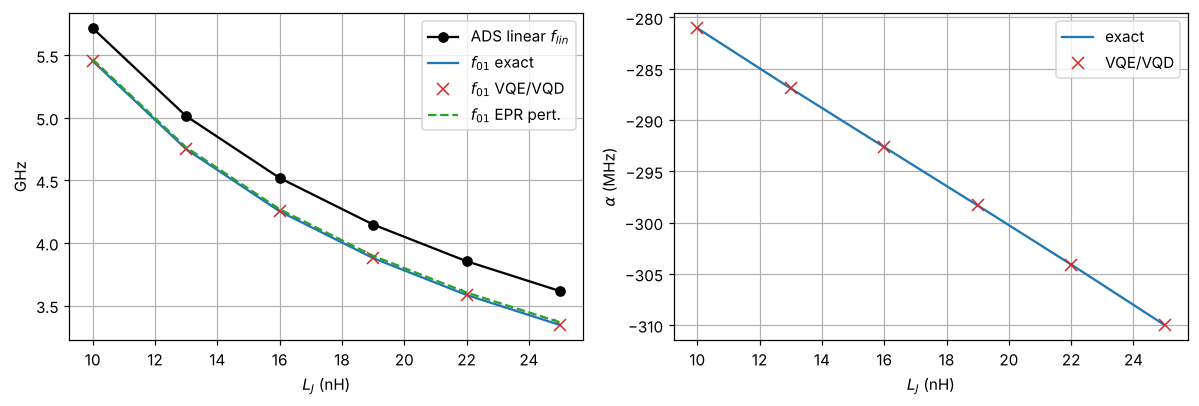

In [15]:
if os.path.exists("ads_sweep.csv"):
    sw = pd.read_csv("ads_sweep.csv"); synthetic = False
else:
    LJs = np.linspace(10, 25, 6)
    sw = pd.DataFrame(dict(LJ_nH=LJs, f_lin_GHz=1/(2*np.pi*np.sqrt(LJs*1e-9*ADS["C_sigma_fF"]*1e-15))/1e9)); synthetic = True
if "p_J" not in sw: sw["p_J"] = ADS["p_J"]

rows = []
for _, s in sw.iterrows():
    EJ_s = phi0**2/(s.LJ_nH*1e-9)/h/1e9
    r_ = solve_all(s.f_lin_GHz, EJ_s, s.p_J, starts=max(2, N_STARTS//2), seed=int(s.LJ_nH*10))
    rows.append(dict(LJ_nH=s.LJ_nH, EJ_GHz=EJ_s, f_lin=s.f_lin_GHz, f01_exact=r_["EPR exact diag"][0], f01_VQE=r_["EPR VQE/VQD"][0],
                     f01_pert=r_["EPR perturbative"][0], alpha_exact=r_["EPR exact diag"][2], alpha_VQE=r_["EPR VQE/VQD"][2],
                     VQE_err_f01_MHz=1e3*(r_["EPR VQE/VQD"][0]-r_["EPR exact diag"][0]),
                     VQE_err_alpha_MHz=1e3*(r_["EPR VQE/VQD"][2]-r_["EPR exact diag"][2])))
swr = pd.DataFrame(rows); print("SYNTHETIC sweep (replace with ADS data)" if synthetic else "ADS sweep")
print(swr.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(swr.LJ_nH, swr.f_lin, "k-o", label="ADS linear $f_{lin}$"); ax[0].plot(swr.LJ_nH, swr.f01_exact, "C0-", label="$f_{01}$ exact")
ax[0].plot(swr.LJ_nH, swr.f01_VQE, "C3x", ms=8, label="$f_{01}$ VQE/VQD"); ax[0].plot(swr.LJ_nH, swr.f01_pert, "C2--", label="$f_{01}$ EPR pert.")
ax[0].set_xlabel("$L_J$ (nH)"); ax[0].set_ylabel("GHz"); ax[0].legend()
ax[1].plot(swr.LJ_nH, 1e3*swr.alpha_exact, "C0-", label="exact"); ax[1].plot(swr.LJ_nH, 1e3*swr.alpha_VQE, "C3x", ms=8, label="VQE/VQD")
ax[1].set_xlabel("$L_J$ (nH)"); ax[1].set_ylabel("$\\alpha$ (MHz)"); ax[1].legend(); plt.tight_layout(); plt.show()

## 11. Summary

Read the results as three separate error budgets:

| Error source | Where assessed | Expected behaviour |
|---|---|---|
| Basis truncation | Section 2 and 4 | negligible at $d=16$ for $E_J/E_C\ge20$ |
| Variational optimisation | Section 8 | depends on depth and starts; $E_2$ worst because VQD errors accumulate |
| Measurement/hardware noise | Section 9 | large Pauli coefficients ($4E_Cn^2$) make shot cost high; depolarising noise rescales frequencies |
| **EPR/EM model (ADS)** | Section 10 | **dominates in practice**: $E_J$ estimate, $C_J$, and EM accuracy (about 5% on anharmonicity in Minev et al.) |

**Claim supported:** VQE/VQD works as an alternative eigensolver behind EPR on a single-mode model, validated against exact diagonalisation. It does not improve EPR's accuracy, which is limited by the EM model, not by diagonalisation. Any advantage would concern scaling with the number of modes ($d^M$ classically vs $M\log_2 d$ qubits), not demonstrated at this size.

**Extension to coupled transmon-resonator:** build two Fock operators $a_q, a_c$, set $\hat\varphi=\varphi_q(a_q+a_q^\dagger)+\varphi_c(a_c+a_c^\dagger)$ with $\varphi_m^2=p_m\hbar\omega_m/2E_J$ ($p_q+p_c=1$), and check $\alpha_q,\alpha_c,\chi_{qc}$ against Eqs. 9–11.